# Preprocessing and Source Leakage Investigation

LRNG: National (India) | CC: Human Values | SDG: 3 | Data: Time series | Thrust: Intelligent Edge Technologies | Screening aid only

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score

np.random.seed(42)
sys.path.append("..")

from data_loading.pads_loader import load_pads_metadata, filter_pads_cohort, load_all_pads_recordings
from data_loading.epilepsy_loader import load_epilepsy_dataset
from data_loading.unified_loader import (
    build_pads_within_source_dataset,
    build_uea_within_source_dataset,
    build_unified_dataset
)
from preprocessing.normalization import (
    per_window_znorm,
    extract_normalized_psd,
    augment_random_scale,
    augment_additive_noise
)

Preprocessing: 2 s setup trim on PADS tremor tasks, 16 Hz downsampling, 3-7.5 Hz bandpass, and per-window de-meaning

In [2]:
pads_root = os.path.join("..", "data", "pads parkinsons-disease smartwatch dataset-1.0.0")
uea_dir = os.path.join("..", "data", "Epilepsy")

pads_w, pads_m = build_pads_within_source_dataset(pads_root, tasks=None, apply_bandpass=True, demean=True)
uea_w, uea_m = build_uea_within_source_dataset(uea_dir, apply_bandpass=True, demean=True)
demo_w, demo_m = build_unified_dataset(pads_root, uea_dir, tasks=None, apply_bandpass=True, demean=True)

print("PADS within-source tremor windows shape:", pads_w.shape)
print("PADS cohort label breakdown:")
print(pads_m["cohort_label"].value_counts())

print("\nUEA within-source windows shape:", uea_w.shape)
print("UEA cohort label breakdown:")
print(uea_m["cohort_label"].value_counts())
print("UEA split breakdown:")
print(uea_m["split"].value_counts())

print("\nDemonstration mixed windows shape:", demo_w.shape)
print(demo_m["cohort_label"].value_counts())

PADS within-source tremor windows shape: (25500, 48, 3)
PADS cohort label breakdown:
cohort_label
Parkinsons-like    18224
Normal              5372
ET-like             1904
Name: count, dtype: int64

UEA within-source windows shape: (1925, 48, 3)
UEA cohort label breakdown:
cohort_label
Normal                      1449
Seizure-like (simulated)     476
Name: count, dtype: int64
UEA split breakdown:
split
test     966
train    959
Name: count, dtype: int64

Demonstration mixed windows shape: (27425, 48, 3)
cohort_label
Parkinsons-like             18224
Normal                       6821
ET-like                      1904
Seizure-like (simulated)      476
Name: count, dtype: int64


Verification of AUC and Balanced Accuracy from identical decision_function per fold

In [3]:
pads_norm_idx = pads_m[pads_m["cohort_label"] == "Normal"].index.values
uea_norm_idx = uea_m[uea_m["cohort_label"] == "Normal"].index.values
n_norm = min(len(pads_norm_idx), len(uea_norm_idx))
np.random.seed(42)
sub_pads_norm = np.random.choice(pads_norm_idx, n_norm, replace=False)
sub_uea_norm = uea_norm_idx[:n_norm]

X_check = np.concatenate([pads_w[sub_pads_norm], uea_w[sub_uea_norm]], axis=0)
y_check = np.array([0]*n_norm + [1]*n_norm)
X_check_flat = X_check.reshape(len(X_check), -1)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("=== Decision Function vs Predict Proba Verification Across Folds ===")
for fold, (tr, te) in enumerate(skf.split(X_check_flat, y_check)):
    clf = LogisticRegression(max_iter=300, random_state=42)
    clf.fit(X_check_flat[tr], y_check[tr])
    
    dec_scores = clf.decision_function(X_check_flat[te])
    preds_from_dec = (dec_scores >= 0).astype(int)
    preds_from_predict = clf.predict(X_check_flat[te])
    
    pos_idx = np.where(clf.classes_ == 1)[0][0]
    probs = clf.predict_proba(X_check_flat[te])[:, pos_idx]
    
    bacc = balanced_accuracy_score(y_check[te], preds_from_dec)
    auc_from_dec = roc_auc_score(y_check[te], dec_scores)
    auc_from_prob = roc_auc_score(y_check[te], probs)
    
    print(f"Fold {fold}: Match={np.array_equal(preds_from_dec, preds_from_predict)} | "
          f"BalancedAcc={bacc:.4f} | AUC(dec)={auc_from_dec:.4f} | AUC(prob)={auc_from_prob:.4f}")

=== Decision Function vs Predict Proba Verification Across Folds ===
Fold 0: Match=True | BalancedAcc=0.7034 | AUC(dec)=0.4823 | AUC(prob)=0.4823
Fold 1: Match=True | BalancedAcc=0.6879 | AUC(dec)=0.4722 | AUC(prob)=0.4722
Fold 2: Match=True | BalancedAcc=0.6810 | AUC(dec)=0.4368 | AUC(prob)=0.4368
Fold 3: Match=True | BalancedAcc=0.6990 | AUC(dec)=0.4730 | AUC(prob)=0.4730
Fold 4: Match=True | BalancedAcc=0.7155 | AUC(dec)=0.5106 | AUC(prob)=0.5106


Trivial-feature leakage tests on raw and demeaned signals: per-window DC, RMS, and gravity-vector norm

In [4]:
pads_raw_w, pads_raw_m = build_pads_within_source_dataset(pads_root, tasks=None, apply_bandpass=False, demean=False)
uea_raw_w, uea_raw_m = build_uea_within_source_dataset(uea_dir, apply_bandpass=False, demean=False)

def compute_trivial_features(windows_arr):
    dc = np.abs(np.mean(windows_arr, axis=1)).mean(axis=1)
    rms = np.sqrt(np.mean(windows_arr**2, axis=(1, 2)))
    gnorm = np.linalg.norm(np.mean(windows_arr, axis=1), axis=1)
    return dc, rms, gnorm

X_norm_raw_bal = np.concatenate([pads_raw_w[sub_pads_norm], uea_raw_w[sub_uea_norm]], axis=0)
X_norm_dm_bal = np.concatenate([pads_w[sub_pads_norm], uea_w[sub_uea_norm]], axis=0)
y_norm_bal = np.array([0]*n_norm + [1]*n_norm)

dc_norm_raw, rms_norm_raw, gnorm_norm_raw = compute_trivial_features(X_norm_raw_bal)
dc_norm_dm, rms_norm_dm, gnorm_norm_dm = compute_trivial_features(X_norm_dm_bal)

pads_ts_raw_idx = pads_raw_m[pads_raw_m["cohort_label"].isin(["Parkinsons-like", "ET-like"])].index.values
uea_ts_raw_idx = uea_raw_m[uea_raw_m["cohort_label"] == "Seizure-like (simulated)"].index.values
n_ts = len(uea_ts_raw_idx)
np.random.seed(42)
sub_pads_ts = np.random.choice(pads_ts_raw_idx, n_ts, replace=False)
sub_uea_ts = uea_ts_raw_idx

X_ts_raw_bal = np.concatenate([pads_raw_w[sub_pads_ts], uea_raw_w[sub_uea_ts]], axis=0)
X_ts_dm_bal = np.concatenate([pads_w[sub_pads_ts], uea_w[sub_uea_ts]], axis=0)
y_ts_bal = np.array([0]*n_ts + [1]*n_ts)

dc_ts_raw, rms_ts_raw, gnorm_ts_raw = compute_trivial_features(X_ts_raw_bal)
dc_ts_dm, rms_ts_dm, gnorm_ts_dm = compute_trivial_features(X_ts_dm_bal)

trivial_records = [
    {"Test": "Normal Source (Raw)", "DC_AUC": roc_auc_score(y_norm_bal, dc_norm_raw), "RMS_AUC": roc_auc_score(y_norm_bal, rms_norm_raw), "Gravity_Norm_AUC": roc_auc_score(y_norm_bal, gnorm_norm_raw)},
    {"Test": "Normal Source (Demeaned)", "DC_AUC": roc_auc_score(y_norm_bal, dc_norm_dm), "RMS_AUC": roc_auc_score(y_norm_bal, rms_norm_dm), "Gravity_Norm_AUC": roc_auc_score(y_norm_bal, gnorm_norm_dm)},
    {"Test": "Tremor vs Seizure (Raw)", "DC_AUC": roc_auc_score(y_ts_bal, dc_ts_raw), "RMS_AUC": roc_auc_score(y_ts_bal, rms_ts_raw), "Gravity_Norm_AUC": roc_auc_score(y_ts_bal, gnorm_ts_raw)},
    {"Test": "Tremor vs Seizure (Demeaned)", "DC_AUC": roc_auc_score(y_ts_bal, dc_ts_dm), "RMS_AUC": roc_auc_score(y_ts_bal, rms_ts_dm), "Gravity_Norm_AUC": roc_auc_score(y_ts_bal, gnorm_ts_dm)}
]

trivial_df = pd.DataFrame(trivial_records)
os.makedirs(os.path.join("..", "results", "metrics"), exist_ok=True)
trivial_df.to_csv(os.path.join("..", "results", "metrics", "trivial_features_auc.csv"), index=False)
print("=== Trivial Feature Leakage Test (AUC per feature alone) ===")
print(trivial_df.to_string(index=False))

=== Trivial Feature Leakage Test (AUC per feature alone) ===
                        Test   DC_AUC  RMS_AUC  Gravity_Norm_AUC
         Normal Source (Raw) 0.999670 1.000000          0.999666
    Normal Source (Demeaned) 0.997415 0.999426          0.997798
     Tremor vs Seizure (Raw) 0.996725 0.995807          0.996500
Tremor vs Seizure (Demeaned) 0.980987 0.991884          0.983101


Normal activity source leakage on balanced subsamples: evaluating accuracy against the 50.0% majority baseline

In [5]:
variants_norm = {
    "Demeaned (Gravity Removed)": X_norm_dm_bal,
    "Per-Window Z-Norm": per_window_znorm(X_norm_dm_bal),
    "Normalized PSD": np.array([extract_normalized_psd(w) for w in X_norm_dm_bal]),
    "Augmented (Scale + Noise)": augment_additive_noise(augment_random_scale(per_window_znorm(X_norm_dm_bal), random_state=42), random_state=42)
}

norm_balanced_records = []

for var_name, X_var in variants_norm.items():
    X_flat = X_var.reshape(len(X_var), -1)
    accs, baccs, aucs = [], [], []
    for tr, te in skf.split(X_flat, y_norm_bal):
        clf = LogisticRegression(max_iter=300, random_state=42)
        clf.fit(X_flat[tr], y_norm_bal[tr])
        preds = clf.predict(X_flat[te])
        pos_idx = np.where(clf.classes_ == 1)[0][0]
        probs = clf.predict_proba(X_flat[te])[:, pos_idx]
        accs.append(accuracy_score(y_norm_bal[te], preds))
        baccs.append(balanced_accuracy_score(y_norm_bal[te], preds))
        aucs.append(roc_auc_score(y_norm_bal[te], probs))
    norm_balanced_records.append({
        "Condition": var_name,
        "Majority_Baseline": 0.5000,
        "Accuracy_Mean": np.mean(accs),
        "Accuracy_Std": np.std(accs),
        "Balanced_Accuracy_Mean": np.mean(baccs),
        "Balanced_Accuracy_Std": np.std(baccs),
        "ROC_AUC_Mean": np.mean(aucs),
        "ROC_AUC_Std": np.std(aucs)
    })

leakage_normal_bal_df = pd.DataFrame(norm_balanced_records)
leakage_normal_bal_df.to_csv(os.path.join("..", "results", "metrics", "leakage_test_normal_balanced.csv"), index=False)
print("=== Normal Source Leakage on Balanced Subsamples (N=2898) ===")
print(leakage_normal_bal_df.to_string(index=False))
print("\nNote: PADS Normal (seated rest) and UEA Normal (walking, running, sawing) represent fundamentally different activities; this test conflates device with activity context.")

=== Normal Source Leakage on Balanced Subsamples (N=2898) ===
                 Condition  Majority_Baseline  Accuracy_Mean  Accuracy_Std  Balanced_Accuracy_Mean  Balanced_Accuracy_Std  ROC_AUC_Mean  ROC_AUC_Std
Demeaned (Gravity Removed)                0.5       0.697384      0.011909                0.697381               0.012040      0.474997     0.023646
         Per-Window Z-Norm                0.5       0.693242      0.008851                0.693243               0.008838      0.469825     0.012315
            Normalized PSD                0.5       0.887506      0.004604                0.887510               0.004601      0.960983     0.002746
 Augmented (Scale + Noise)                0.5       0.601455      0.007650                0.601445               0.007735      0.474470     0.016770

Note: PADS Normal (seated rest) and UEA Normal (walking, running, sawing) represent fundamentally different activities; this test conflates device with activity context.


Tremor versus simulated seizure source separation on balanced subsamples

In [6]:
variants_ts = {
    "Demeaned (Gravity Removed)": X_ts_dm_bal,
    "Per-Window Z-Norm": per_window_znorm(X_ts_dm_bal),
    "Normalized PSD": np.array([extract_normalized_psd(w) for w in X_ts_dm_bal]),
    "Augmented (Scale + Noise)": augment_additive_noise(augment_random_scale(per_window_znorm(X_ts_dm_bal), random_state=42), random_state=42)
}

ts_balanced_records = []

for var_name, X_var in variants_ts.items():
    X_flat = X_var.reshape(len(X_var), -1)
    accs, baccs, aucs = [], [], []
    for tr, te in skf.split(X_flat, y_ts_bal):
        clf = LogisticRegression(max_iter=300, random_state=42)
        clf.fit(X_flat[tr], y_ts_bal[tr])
        preds = clf.predict(X_flat[te])
        pos_idx = np.where(clf.classes_ == 1)[0][0]
        probs = clf.predict_proba(X_flat[te])[:, pos_idx]
        accs.append(accuracy_score(y_ts_bal[te], preds))
        baccs.append(balanced_accuracy_score(y_ts_bal[te], preds))
        aucs.append(roc_auc_score(y_ts_bal[te], probs))
    ts_balanced_records.append({
        "Condition": var_name,
        "Majority_Baseline": 0.5000,
        "Accuracy_Mean": np.mean(accs),
        "Accuracy_Std": np.std(accs),
        "Balanced_Accuracy_Mean": np.mean(baccs),
        "Balanced_Accuracy_Std": np.std(baccs),
        "ROC_AUC_Mean": np.mean(aucs),
        "ROC_AUC_Std": np.std(aucs)
    })

leakage_ts_bal_df = pd.DataFrame(ts_balanced_records)
leakage_ts_bal_df.to_csv(os.path.join("..", "results", "metrics", "leakage_test_tremor_seizure_balanced.csv"), index=False)
print("=== Tremor vs Seizure Source Separation on Balanced Subsamples (N=952) ===")
print(leakage_ts_bal_df.to_string(index=False))
print("\nWarning: Seizure-like vs PD/ET separation is not validated until own MPU6050 recordings exist. The classifier distinguishes device origin alongside movement characteristics due to cross-source confounding.")

=== Tremor vs Seizure Source Separation on Balanced Subsamples (N=952) ===
                 Condition  Majority_Baseline  Accuracy_Mean  Accuracy_Std  Balanced_Accuracy_Mean  Balanced_Accuracy_Std  ROC_AUC_Mean  ROC_AUC_Std
Demeaned (Gravity Removed)                0.5       0.679631      0.009064                0.679583               0.009134      0.489070     0.033655
         Per-Window Z-Norm                0.5       0.692240      0.007269                0.692215               0.006923      0.486331     0.026589
            Normalized PSD                0.5       0.866619      0.013308                0.866656               0.013257      0.939950     0.006137
 Augmented (Scale + Noise)                0.5       0.679631      0.011684                0.679616               0.010933      0.490444     0.028507



Visualizing source prediction balanced accuracy across mitigations on balanced subsamples

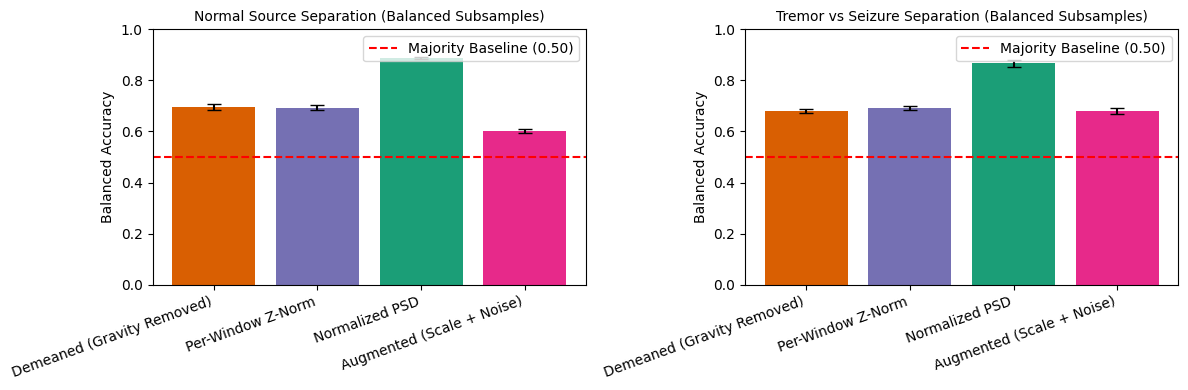

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    leakage_normal_bal_df["Condition"],
    leakage_normal_bal_df["Balanced_Accuracy_Mean"],
    yerr=leakage_normal_bal_df["Balanced_Accuracy_Std"],
    capsize=5, color=["#d95f02", "#7570b3", "#1b9e77", "#e7298a"]
)
axes[0].axhline(0.5, color="red", linestyle="--", label="Majority Baseline (0.50)")
axes[0].set_ylim(0.0, 1.0)
axes[0].set_ylabel("Balanced Accuracy")
axes[0].set_title("Normal Source Separation (Balanced Subsamples)", fontsize=10)
axes[0].set_xticklabels(leakage_normal_bal_df["Condition"], rotation=20, ha="right")
axes[0].legend(loc="upper right")

axes[1].bar(
    leakage_ts_bal_df["Condition"],
    leakage_ts_bal_df["Balanced_Accuracy_Mean"],
    yerr=leakage_ts_bal_df["Balanced_Accuracy_Std"],
    capsize=5, color=["#d95f02", "#7570b3", "#1b9e77", "#e7298a"]
)
axes[1].axhline(0.5, color="red", linestyle="--", label="Majority Baseline (0.50)")
axes[1].set_ylim(0.0, 1.0)
axes[1].set_ylabel("Balanced Accuracy")
axes[1].set_title("Tremor vs Seizure Separation (Balanced Subsamples)", fontsize=10)
axes[1].set_xticklabels(leakage_ts_bal_df["Condition"], rotation=20, ha="right")
axes[1].legend(loc="upper right")

plt.tight_layout()
os.makedirs(os.path.join("..", "results", "plots"), exist_ok=True)
plt.savefig(os.path.join("..", "results", "plots", "leakage_balanced_mitigations.png"))
plt.show()

Project redesign: saving within-source datasets for primary models and mixed dataset for demonstration

In [8]:
os.makedirs(os.path.join("..", "results"), exist_ok=True)

np.savez_compressed(os.path.join("..", "results", "pads_within_source_16hz.npz"), windows=pads_w)
pads_m.to_csv(os.path.join("..", "results", "pads_within_source_metadata.csv"), index=False)

np.savez_compressed(os.path.join("..", "results", "uea_within_source_16hz.npz"), windows=uea_w)
uea_m.to_csv(os.path.join("..", "results", "uea_within_source_metadata.csv"), index=False)

np.savez_compressed(os.path.join("..", "results", "demonstration_unified_16hz.npz"), windows=demo_w)
demo_m.to_csv(os.path.join("..", "results", "demonstration_unified_metadata.csv"), index=False)

print("Saved all preprocessed datasets to results/:")
print("1. Track A (Primary): PADS within-source (Healthy vs PD vs ET on tremor tasks, 5-fold subject CV)")
print("2. Track B (Primary): UEA within-source (Seizure-like simulated vs Normal activities, train/test split)")
print("3. Track C (Demonstration): Mixed 4-class unified dataset (labeled demonstration only)")

Saved all preprocessed datasets to results/:
1. Track A (Primary): PADS within-source (Healthy vs PD vs ET on tremor tasks, 5-fold subject CV)
2. Track B (Primary): UEA within-source (Seizure-like simulated vs Normal activities, train/test split)
3. Track C (Demonstration): Mixed 4-class unified dataset (labeled demonstration only)
